# Notebook 02: Adaptive ROI Cropping & Soil Noise Preprocessing
**Project:** `Fabric_FYP` — Quantitative Color and Texture Analysis of Degraded Cotton and Polyester Fabrics

This notebook prepares all eligible images (`Grade A` and `Grade B`) audited in **Notebook 01** for quantitative feature extraction by splitting preprocessing into two dedicated analytical branches:
1. **Color Extraction Branch (`data/processed/cropped_roi/`):** Extracts each image's custom high-focus Region of Interest (`roi_x, roi_y, roi_w, roi_h`) without intensity smoothing, preserving authentic surface discoloration and environmental staining for **CIELAB ($\Delta E$)** and **HSV** analysis.
2. **Texture Extraction Branch (`data/processed/filtered_texture/`):** Converts cropped ROIs into 8-bit grayscale and applies a selective **`1-px` radius (`3 × 3` kernel) median filter** *exclusively* to visually soil-stained **Grade B** outdoor images, suppressing discrete dirt speckles while leaving clean **Grade A** weaves completely unfiltered.

In [1]:
import sys
import json
import importlib
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# Resolve Fabric_FYP project root dynamically
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert PROJECT_ROOT.name == "Fabric_FYP", f"Expected project root 'Fabric_FYP', got '{PROJECT_ROOT.name}'"

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import fabric_taphonomy.preprocessing as prep
importlib.reload(prep)  # Always load latest saved version of preprocessing.py
from fabric_taphonomy.preprocessing import run_batch_preprocessing

# Define input and output paths
RAW_DIR = PROJECT_ROOT / "data" / "raw"
CROPPED_DIR = PROJECT_ROOT / "data" / "processed" / "cropped_roi"
TEXTURE_DIR = PROJECT_ROOT / "data" / "processed" / "filtered_texture"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
PARAMS_DIR = PROJECT_ROOT / "outputs" / "parameters"

CROPPED_DIR.mkdir(parents=True, exist_ok=True)
TEXTURE_DIR.mkdir(parents=True, exist_ok=True)

# Load inventory and calibrated preprocessing parameters from Notebook 01
inventory_df = pd.read_csv(TABLES_DIR / "dataset_inventory.csv")
with open(PARAMS_DIR / "roi_preprocessing_config.json", "r") as f:
    roi_config = json.load(f)

plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300})
print(f"Loaded dataset inventory: {len(inventory_df)} total images | {inventory_df['eligible'].sum()} eligible (Grade A + B)")
print(f"Loaded config -> Crop mode: {roi_config['crop_mode']} | Grade B Median Kernel: {roi_config['median_filter_ksize_grade_b']}x{roi_config['median_filter_ksize_grade_b']}")

Loaded dataset inventory: 130 total images | 130 eligible (Grade A + B)
Loaded config -> Crop mode: adaptive_variable_high_focus | Grade B Median Kernel: 3x3


## 1. Adaptive High-Focus ROI Cropping & Dual-Branch Export
Raw AmScope microscope captures (`1228 × 922` pixels) exhibit dark illumination falloff (vignetting) in the upper corners and occasional depth-of-field blurring across warped fabric edges. Using the per-image coordinates (`roi_x`, `roi_y`, `roi_w`, `roi_h`) computed in Notebook 01, each eligible image is cropped to its sharpest, highest-data fabric window.

All processed images are saved in **lossless `.png` format** rather than re-compressed `.jpg` files. Avoiding secondary JPEG compression prevents `8 × 8` block artifacts from distorting downstream **GLCM** texture matrices and **Canny** edge density measurements.

In [2]:
# Run batch cropping and selective Grade B median filtering
manifest_df = run_batch_preprocessing(
    inventory_df=inventory_df,
    raw_dir=RAW_DIR,
    cropped_dir=CROPPED_DIR,
    texture_dir=TEXTURE_DIR,
    median_ksize=int(roi_config["median_filter_ksize_grade_b"]),
)

# Save updated manifest linking each image_id to its processed file paths
manifest_path = TABLES_DIR / "preprocessed_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

# Verify output file counts match eligible images
n_grade_a = (manifest_df["qc_grade"] == "A").sum()
n_grade_b = (manifest_df["qc_grade"] == "B").sum()

print(f"Batch preprocessing complete! Saved manifest to: {manifest_path}")
print(f"  - Color ROIs saved in '{CROPPED_DIR.relative_to(PROJECT_ROOT)}'        : {len(manifest_df)} lossless PNGs")
print(f"  - Texture Grayscale saved in '{TEXTURE_DIR.relative_to(PROJECT_ROOT)}': {len(manifest_df)} lossless PNGs")
print(f"    * Grade A (unfiltered grayscale)         : {n_grade_a} images")
print(f"    * Grade B (3x3 median-filtered grayscale): {n_grade_b} images")

display(manifest_df[["image_id", "fabric", "group_code", "day", "roi_w", "roi_h", "qc_grade", "cropped_rel_path"]].head(10))

Batch preprocessing complete! Saved manifest to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/tables/preprocessed_manifest.csv
  - Color ROIs saved in 'data/processed/cropped_roi'        : 130 lossless PNGs
  - Texture Grayscale saved in 'data/processed/filtered_texture': 130 lossless PNGs
    * Grade A (unfiltered grayscale)         : 52 images
    * Grade B (3x3 median-filtered grayscale): 78 images


,image_id,fabric,group_code,day,roi_w,roi_h,qc_grade,cropped_rel_path
0,C1_D10_8,Cotton,C1,20,600,500,B,C1/C1_D10_8.png
1,C1_D11_19,Cotton,C1,22,850,650,B,C1/C1_D11_19.png
2,C1_D12_15,Cotton,C1,24,600,500,B,C1/C1_D12_15.png
3,C1_D13_4,Cotton,C1,26,850,650,B,C1/C1_D13_4.png
4,C1_D14_20,Cotton,C1,28,600,500,B,C1/C1_D14_20.png
5,C1_D15_10,Cotton,C1,30,600,500,B,C1/C1_D15_10.png
6,C1_D1_1,Cotton,C1,2,850,650,A,C1/C1_D1_1.png
7,C1_D2_18,Cotton,C1,4,850,650,B,C1/C1_D2_18.png
8,C1_D3_16,Cotton,C1,6,850,650,B,C1/C1_D3_16.png
9,C1_D4_14,Cotton,C1,8,850,650,B,C1/C1_D4_14.png


## 2. Visual Verification: Raw Image vs. Adaptive High-Focus ROI Crop
To confirm that dark corner vignetting is cleanly removed while woven yarn geometry remains intact across both fabric types, one representative **Cotton** sample and one **Polyester** sample are plotted below before and after adaptive ROI cropping.

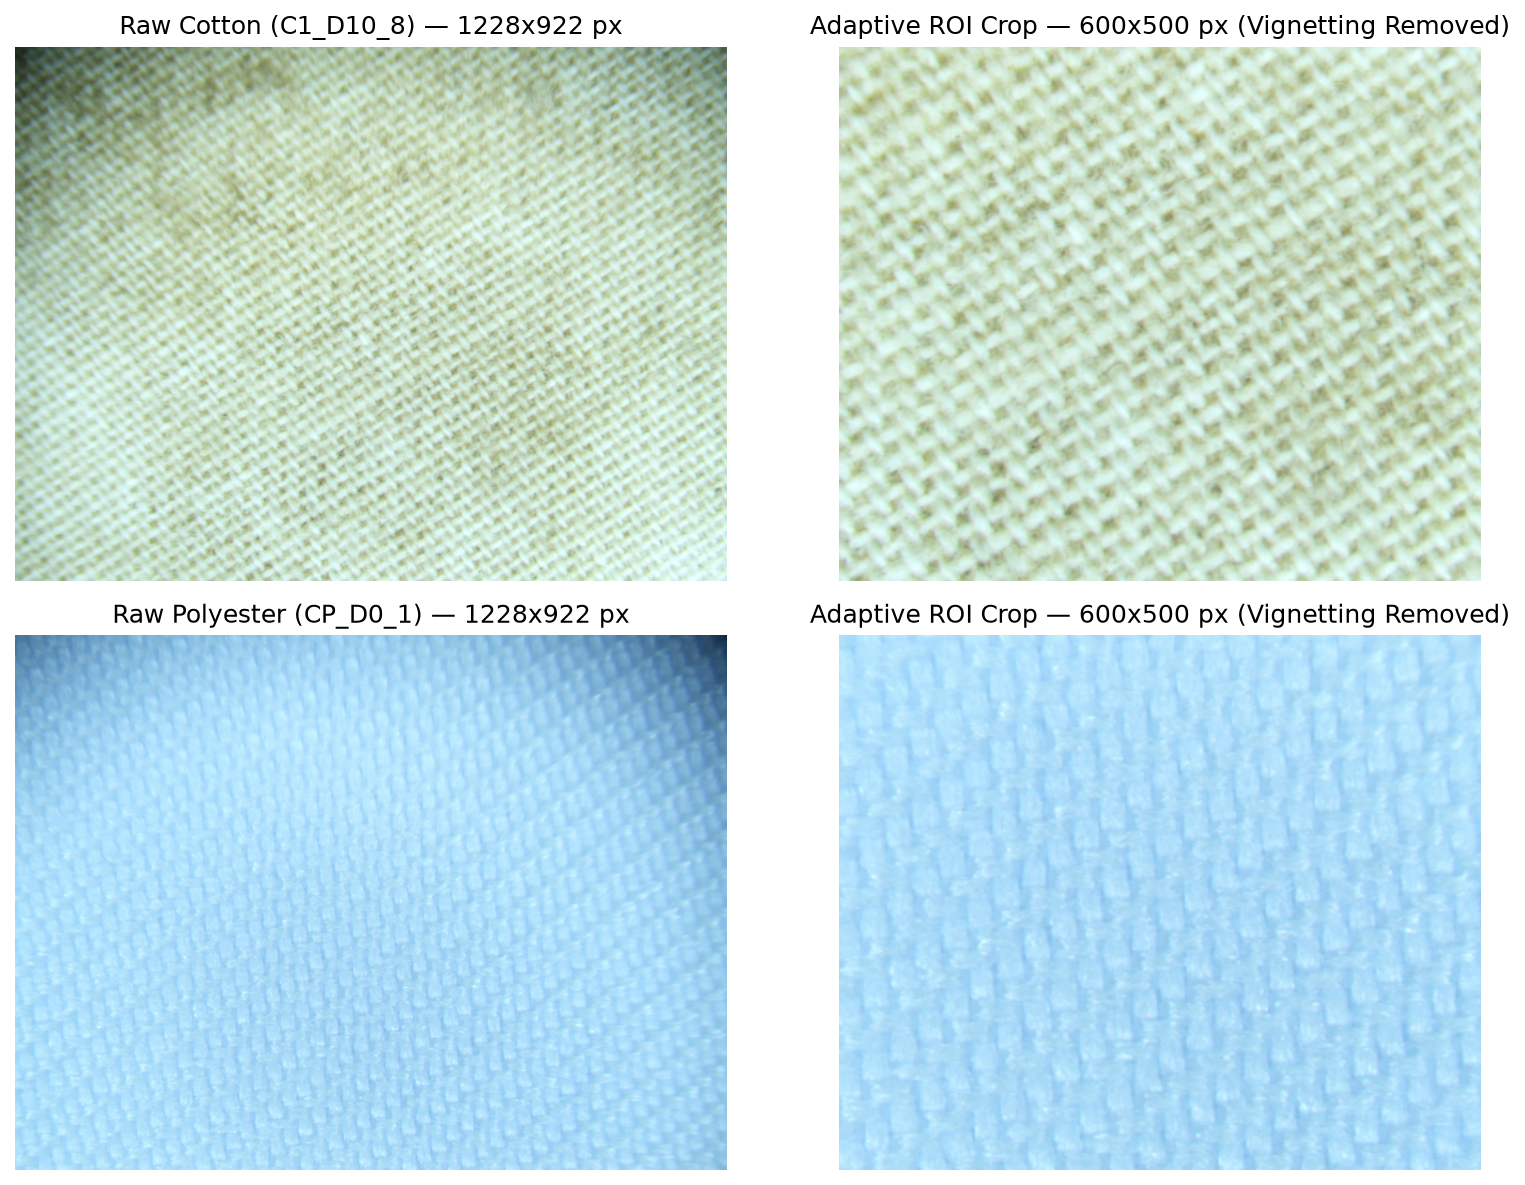

Saved cropping verification figure to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures/preprocessing_roi_verification.png


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for row_idx, fab in enumerate(["Cotton", "Polyester"]):
    sample = manifest_df[manifest_df["fabric"] == fab].iloc[0]

    raw_rgb = cv2.cvtColor(cv2.imread(str(RAW_DIR / sample["rel_path"])), cv2.COLOR_BGR2RGB)
    crop_rgb = cv2.cvtColor(cv2.imread(str(CROPPED_DIR / sample["cropped_rel_path"])), cv2.COLOR_BGR2RGB)

    axes[row_idx, 0].imshow(raw_rgb)
    axes[row_idx, 0].set_title(f"Raw {fab} ({sample['image_id']}) — {sample['width_px']}x{sample['height_px']} px")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(crop_rgb)
    axes[row_idx, 1].set_title(f"Adaptive ROI Crop — {sample['roi_w']}x{sample['roi_h']} px (Vignetting Removed)")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
crop_fig_path = FIGURES_DIR / "preprocessing_roi_verification.png"
plt.savefig(crop_fig_path, dpi=300)
plt.show()
print("Saved cropping verification figure to:", crop_fig_path)

## 3. Visual Verification: Selective Median Filtering on Soil-Stained Grade B Samples
Outdoor samples classified as **Grade B** contain localized soil grains and organic debris deposited during environmental exposure. Applying a **`1-px` radius (`3 × 3` kernel) median filter** replaces isolated salt-and-pepper soil pixel spikes with the local neighborhood median intensity, suppressing particulate noise while preserving edge sharpness along cotton twill and polyester gabardine yarns.

The comparison below illustrates an unfiltered Grade B grayscale ROI alongside its median-filtered counterpart and a zoomed-in weave patch.

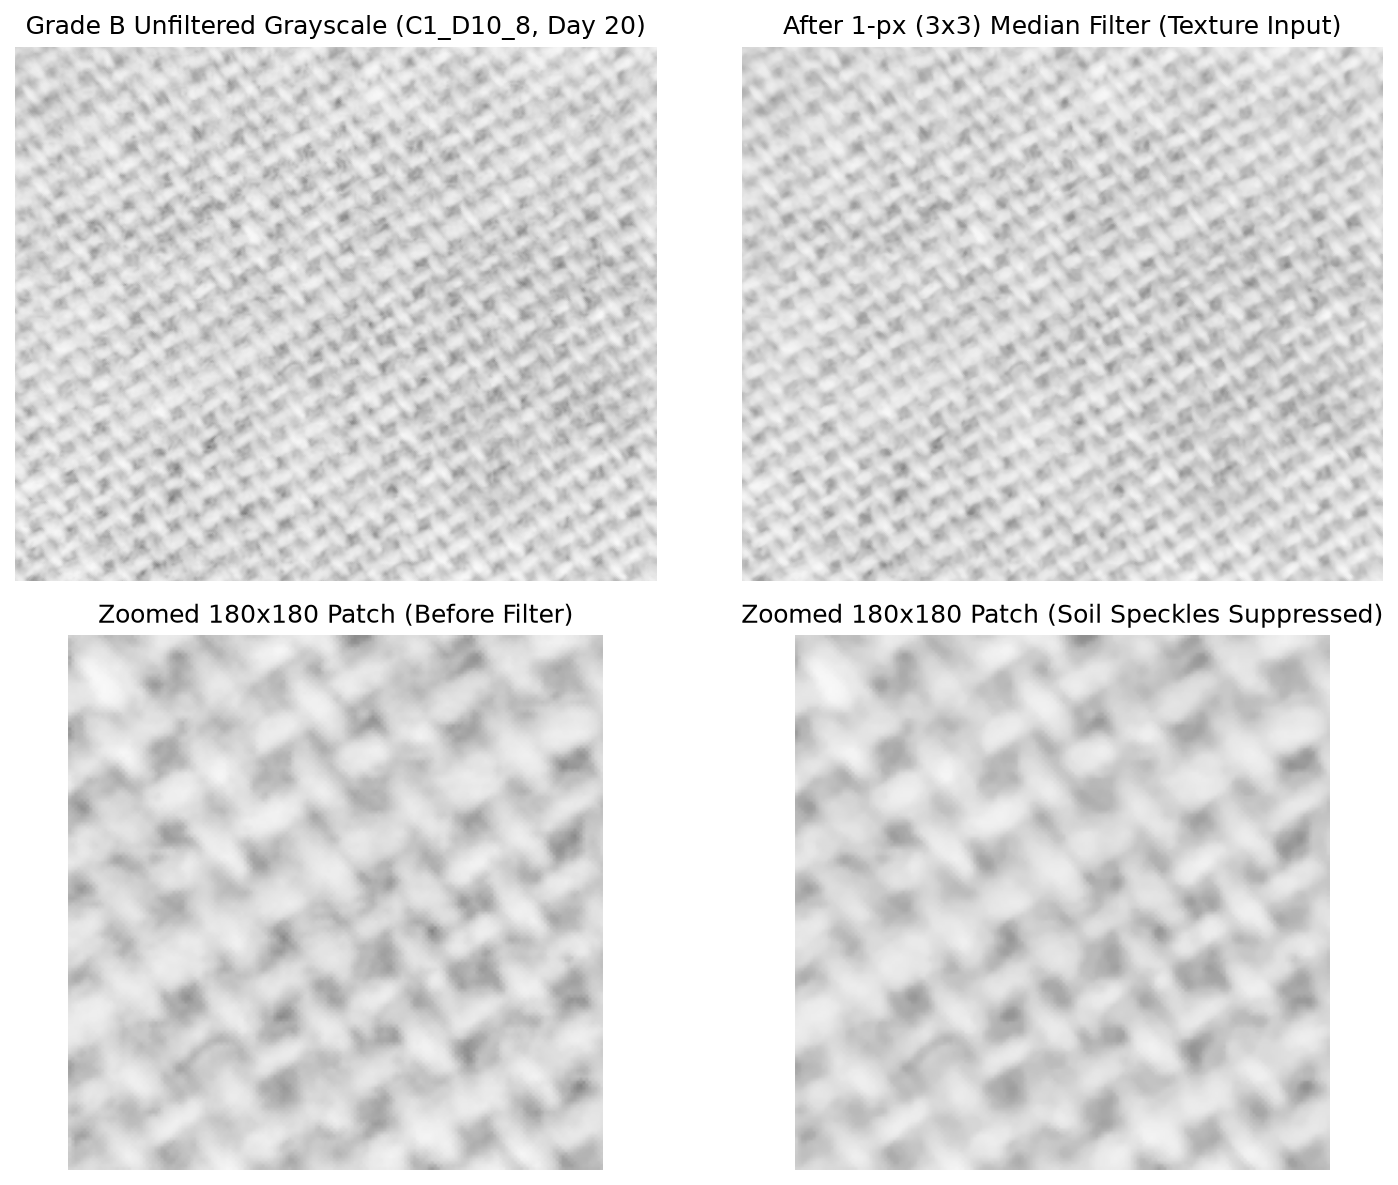

Saved Grade B filter verification figure to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures/grade_b_median_filter_comparison.png


In [4]:
grade_b_samples = manifest_df[manifest_df["qc_grade"] == "B"]

if len(grade_b_samples) > 0:
    # Pick the most visibly soil-stained Grade B sample for clear visual demonstration
    sample_b = grade_b_samples.sort_values("soil_pixel_pct", ascending=False).iloc[0]

    crop_bgr = cv2.imread(str(CROPPED_DIR / sample_b["cropped_rel_path"]))
    unfiltered_gray = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2GRAY)
    filtered_gray = cv2.imread(str(TEXTURE_DIR / sample_b["texture_rel_path"]), cv2.IMREAD_GRAYSCALE)

    # Extract a central 180x180 zoomed-in patch to inspect thread edges vs. soil specks
    zh, zw = unfiltered_gray.shape
    cy, cx = zh // 2, zw // 2
    zoom_unfilt = unfiltered_gray[cy - 90:cy + 90, cx - 90:cx + 90]
    zoom_filt = filtered_gray[cy - 90:cy + 90, cx - 90:cx + 90]

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    axes[0, 0].imshow(unfiltered_gray, cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title(f"Grade B Unfiltered Grayscale ({sample_b['image_id']}, Day {sample_b['day']})")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(filtered_gray, cmap="gray", vmin=0, vmax=255)
    axes[0, 1].set_title("After 1-px (3x3) Median Filter (Texture Input)")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(zoom_unfilt, cmap="gray", vmin=0, vmax=255)
    axes[1, 0].set_title("Zoomed 180x180 Patch (Before Filter)")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(zoom_filt, cmap="gray", vmin=0, vmax=255)
    axes[1, 1].set_title("Zoomed 180x180 Patch (Soil Speckles Suppressed)")
    axes[1, 1].axis("off")

    plt.tight_layout()
    filter_fig_path = FIGURES_DIR / "grade_b_median_filter_comparison.png"
    plt.savefig(filter_fig_path, dpi=300)
    plt.show()
    print("Saved Grade B filter verification figure to:", filter_fig_path)
else:
    print("No Grade B samples found in manifest.")